# Mapas autoorganizados de Kohonen
FIME ICI 7B REDES NEURONALES
Christian David Sanchez Sanchez
Fernando Nicolas Sanchez Montes De Oca

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# parametros generales
SEMILLA = 42
SEMILLA_4 = 42
EPOCAS = 500
ALFA0 = 0.5

# constantes de tiempo del decaimiento exponencial
TAU_ALFA = 200
TAU_SIGMA = 300

Para que α y σ bajen de forma gradual usamos decaimiento exponencial:

α(t) = α₀ · exp(−t / τα)  y  σ(t) = σ₀ · exp(−t / τσ)

Con τα = 200 y τσ = 300, en la época 500 queda α ≈ 0.04 y σ ≈ 0.38 (para σ₀ = 2). Los dos se mantienen positivos y al final el radio casi solo cubre a la BMU

## Funciones del SOM
distancia, BMU, vecindad gaussiana, actualización de pesos y error de cuantizacion

In [2]:
def posiciones_mapa(filas, cols):
    # coordenadas [fila, columna] de cada neurona en la cuadricula
    pos = []
    for i in range(filas):
        for j in range(cols):
            pos.append([i, j])
    return np.array(pos, dtype=float)

def inicializar_pesos(n_neuronas, d, rng):
    # pesos aleatorios entre 0 y 1 (los datos ya estan normalizados)
    return rng.random((n_neuronas, d))

def distancias(x, W):
    # distancia euclidiana de la muestra x a cada neurona
    return np.sqrt(((W - x) ** 2).sum(axis=1))

def buscar_bmu(x, W):
    return np.argmin(distancias(x, W))

def vecindad(c, pos, sigma):
    # h = exp(-||rc - rj||^2 / (2 sigma^2)), la distancia es en el mapa
    d2 = ((pos - pos[c]) ** 2).sum(axis=1)
    return np.exp(-d2 / (2 * sigma ** 2))

def matriz_distancias(X, W):
    # distancia de cada muestra (fila) a cada neurona (columna)
    return np.sqrt(((X[:, None, :] - W[None, :, :]) ** 2).sum(axis=2))

def asignar_bmu(X, W):
    D = matriz_distancias(X, W)
    return D.argmin(axis=1), D

def error_cuantizacion(X, W):
    # promedio de la distancia entre cada muestra y su BMU
    return matriz_distancias(X, W).min(axis=1).mean()

def entrenar(X, W, pos, alfa0, sigma0, epocas, rng, cada=25):
    W = W.copy()
    registro = []
    for t in range(epocas + 1):
        alfa = alfa0 * np.exp(-t / TAU_ALFA)
        sigma = sigma0 * np.exp(-t / TAU_SIGMA)
        # se guarda el error cada 'cada' epocas (antes de entrenar la epoca t)
        if t % cada == 0:
            registro.append([t, alfa, sigma, error_cuantizacion(X, W)])
        if t == epocas:
            break
        # una epoca: todas las muestras en orden aleatorio
        for i in rng.permutation(len(X)):
            x = X[i]
            c = buscar_bmu(x, W)
            h = vecindad(c, pos, sigma)
            W = W + alfa * h[:, None] * (x - W)
    return W, pd.DataFrame(registro, columns=["epoca", "alfa", "sigma", "Eq"])

def normalizar(X, minimo, maximo):
    return (X - minimo) / (maximo - minimo)

def separar(grupos, rng, frac_eval=0.2):
    # separa entrenamiento y evaluacion tomando la misma proporcion de cada grupo
    idx_train, idx_eval = [], []
    for g in np.unique(grupos):
        idx = rng.permutation(np.where(grupos == g)[0])
        n_eval = int(len(idx) * frac_eval)
        idx_eval.extend(idx[:n_eval])
        idx_train.extend(idx[n_eval:])
    return np.sort(idx_train), np.sort(idx_eval)

## Funciones de visualización

In [3]:
def graficar_datos_y_neuronas(ax, X, y, W, filas, cols, nombres, colores):
    # puntos de datos (coloreados solo para interpretar) y neuronas unidas con su vecindad
    for g in colores:
        m = (y == g)
        ax.scatter(X[m, 0], X[m, 1], s=15, color=colores[g], alpha=0.6, label=g)
    for i in range(filas):
        for j in range(cols):
            k = i * cols + j
            if j < cols - 1:
                ax.plot([W[k, 0], W[k + 1, 0]], [W[k, 1], W[k + 1, 1]], "k-", lw=0.8)
            if i < filas - 1:
                ax.plot([W[k, 0], W[k + cols, 0]], [W[k, 1], W[k + cols, 1]], "k-", lw=0.8)
    ax.scatter(W[:, 0], W[:, 1], color="black", marker="s", s=50, zorder=3)
    for k in range(len(W)):
        ax.text(W[k, 0] + 0.01, W[k, 1] + 0.01, str(k + 1), fontsize=8)
    ax.set_xlabel(nombres[0] + " (normalizado)")
    ax.set_ylabel(nombres[1] + " (normalizado)")
    ax.set_title("Datos y neuronas finales")
    ax.legend(fontsize=7)

def graficar_mapa(ax, bmu, y, pos, filas, cols, titulo, colores):
    # cada muestra se dibuja en la casilla de su BMU (con un poco de desplazamiento para que no se encimen)
    rng_g = np.random.default_rng(0)
    cuenta = np.bincount(bmu, minlength=filas * cols)
    for k in range(filas * cols):
        ax.text(pos[k, 1], pos[k, 0] - 0.4, "n=" + str(cuenta[k]), ha="center", fontsize=7)
    for g in colores:
        m = (y == g)
        dx = rng_g.uniform(-0.25, 0.25, m.sum())
        dy = rng_g.uniform(-0.15, 0.25, m.sum())
        ax.scatter(pos[bmu[m], 1] + dx, pos[bmu[m], 0] + dy, s=15, color=colores[g], label=g)
    ax.set_xticks(range(cols)); ax.set_yticks(range(filas))
    ax.set_xlim(-0.6, cols - 0.4); ax.set_ylim(filas - 0.4, -0.6)
    ax.grid(alpha=0.3)
    ax.set_xlabel("columna"); ax.set_ylabel("fila"); ax.set_title(titulo)
    ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)

# 6. Ejercicio 4: implementación computacional

dos características normalizadas, mapa 3×3, pesos iniciales aleatorios con semilla, α₀ = 0.5, σ₀ = 2, 500 épocas, actualización de la BMU y su vecindad gaussiana, y error de cuantización como evaluación.

**Datos.** Se usan dos características numéricas (x1 y x2) generadas con una semilla fija, para que los resultados se puedan repetir. El SOM no conoce los grupos con los que se generaron; la columna `grupo` solo se usa al final para interpretar el mapa.

## 6.1 Preparación de datos

In [4]:
# generacion de datos de dos caracteristicas: 4 grupos de 50 muestras cada uno
rng_datos = np.random.default_rng(SEMILLA_4)

# (media x1, media x2, desviacion x1, desviacion x2) de cada grupo
grupos = {
    "A": (8, 3, 1.5, 1.0),
    "B": (20, 10, 3.0, 2.0),
    "C": (35, 24, 3.5, 3.0),
    "D": (34, 6, 3.0, 1.5),
}
filas_datos = []
for nombre, (m1, m2, s1, s2) in grupos.items():
    x1 = rng_datos.normal(m1, s1, 50)
    x2 = rng_datos.normal(m2, s2, 50)
    for a, b in zip(x1, x2):
        filas_datos.append([a, b, nombre])

datos4 = pd.DataFrame(filas_datos, columns=["x1", "x2", "grupo"])
datos4[["x1", "x2"]] = datos4[["x1", "x2"]].round(2)
datos4.to_csv("datos_ejercicio4.csv", index=False)
print(datos4.shape)
datos4.groupby("grupo").mean().round(2)

(200, 3)


,x1,x2
grupo,,
A,8.14,2.81
B,19.85,10.06
C,34.57,23.99
D,34.41,6.10


In [5]:
columnas4 = ["x1", "x2"]
grupo_real = datos4["grupo"].to_numpy()      # se guarda aparte, no se usa para entrenar
colores4 = {"A": "tab:blue", "B": "tab:orange", "C": "tab:green", "D": "tab:red"}

rng = np.random.default_rng(SEMILLA_4)
idx_train, idx_eval = separar(grupo_real, rng)
print("entrenamiento:", len(idx_train), " evaluacion:", len(idx_eval))

# la normalizacion min-max se calcula SOLO con los datos de entrenamiento
X4_crudo = datos4[columnas4].to_numpy()
min4 = X4_crudo[idx_train].min(axis=0)
max4 = X4_crudo[idx_train].max(axis=0)
print("minimos:", min4, " maximos:", max4)

X4_train = normalizar(X4_crudo[idx_train], min4, max4)
X4_eval = normalizar(X4_crudo[idx_eval], min4, max4)   # puede salirse un poco de [0, 1]
y_train, y_eval = grupo_real[idx_train], grupo_real[idx_eval]

entrenamiento: 160  evaluacion: 40
minimos: [5.07 1.31]  maximos: [45.17 30.28]


## 6.2 Inicialización de pesos

In [6]:
filas, cols = 3, 3
SIGMA0 = 2.0

pos4 = posiciones_mapa(filas, cols)
rng = np.random.default_rng(SEMILLA_4)            # misma semilla para poder repetir el resultado
pesos_ini4 = inicializar_pesos(filas * cols, 2, rng)

tabla_ini = pd.DataFrame(pesos_ini4, columns=columnas4)
tabla_ini.insert(0, "columna", pos4[:, 1].astype(int))
tabla_ini.insert(0, "fila", pos4[:, 0].astype(int))
tabla_ini.index = range(1, 10)
print("Pesos iniciales (normalizados)")
tabla_ini

Pesos iniciales (normalizados)


,fila,columna,x1,x2
1,0,0,0.773956,0.438878
2,0,1,0.858598,0.697368
3,0,2,0.094177,0.975622
4,1,0,0.761140,0.786064
5,1,1,0.128114,0.450386
6,1,2,0.370798,0.926765
7,2,0,0.643865,0.822762
8,2,1,0.443414,0.227239
9,2,2,0.554585,0.063817


## 6.3 Entrenamiento

In [7]:
pesos_fin4, registro4 = entrenar(X4_train, pesos_ini4, pos4, ALFA0, SIGMA0, EPOCAS, rng)

tabla_fin = pd.DataFrame(pesos_fin4, columns=columnas4)
tabla_fin.insert(0, "columna", pos4[:, 1].astype(int))
tabla_fin.insert(0, "fila", pos4[:, 0].astype(int))
tabla_fin.index = range(1, 10)
print("Pesos finales (normalizados)")
tabla_fin

Pesos finales (normalizados)


,fila,columna,x1,x2
1,0,0,0.382263,0.418334
2,0,1,0.277267,0.255500
3,0,2,0.079975,0.055822
4,1,0,0.656670,0.726211
5,1,1,0.394509,0.313673
6,1,2,0.429405,0.186144
7,2,0,0.801150,0.798521
8,2,1,0.670278,0.402029
9,2,2,0.743751,0.174637


## 6.4 Tabla de seguimiento
El error se guardó cada 25 épocas (21 registros); aquí se muestran los de cada 50 épocas

In [8]:
seguimiento = registro4[registro4["epoca"] % 50 == 0]
print(seguimiento.round(4).to_string(index=False))
print("registros guardados:", len(registro4))

 epoca   alfa  sigma     Eq
     0 0.5000 2.0000 0.2035
    50 0.3894 1.6930 0.2261
   100 0.3033 1.4331 0.2048
   150 0.2362 1.2131 0.1949
   200 0.1839 1.0268 0.1376
   250 0.1433 0.8692 0.1064
   300 0.1116 0.7358 0.0857
   350 0.0869 0.6228 0.0749
   400 0.0677 0.5272 0.0734
   450 0.0527 0.4463 0.0702
   500 0.0410 0.3778 0.0635
registros guardados: 21


## 6.5 Asignación de BMU a cada muestra

In [9]:
bmu_train, D_train = asignar_bmu(X4_train, pesos_fin4)
bmu_eval, D_eval = asignar_bmu(X4_eval, pesos_fin4)

# tabla con la BMU de las 200 muestras (el grupo solo se agrega para poder interpretar)
tabla_bmu4 = pd.DataFrame({
    "muestra": np.concatenate([idx_train, idx_eval]),
    "conjunto": ["train"] * len(idx_train) + ["eval"] * len(idx_eval),
    "BMU": np.concatenate([bmu_train, bmu_eval]) + 1,
    "fila": np.concatenate([pos4[bmu_train, 0], pos4[bmu_eval, 0]]).astype(int),
    "columna": np.concatenate([pos4[bmu_train, 1], pos4[bmu_eval, 1]]).astype(int),
    "grupo": np.concatenate([y_train, y_eval]),
}).sort_values("muestra")
tabla_bmu4.to_csv("bmu_ejercicio4.csv", index=False)
tabla_bmu4.head(10)

,muestra,conjunto,BMU,fila,columna,grupo
0,0,train,3,0,2,A
1,1,train,3,0,2,A
2,2,train,3,0,2,A
3,3,train,3,0,2,A
4,4,train,3,0,2,A
160,5,eval,3,0,2,A
5,6,train,3,0,2,A
6,7,train,3,0,2,A
7,8,train,3,0,2,A
8,9,train,3,0,2,A


## 6.6 Evaluación

In [10]:
print("Error de cuantizacion inicial      :", round(registro4["Eq"].iloc[0], 4))
print("Error de cuantizacion final (train):", round(error_cuantizacion(X4_train, pesos_fin4), 4))
print("Error de cuantizacion final (eval) :", round(error_cuantizacion(X4_eval, pesos_fin4), 4))

Error de cuantizacion inicial      : 0.2035
Error de cuantizacion final (train): 0.0635
Error de cuantizacion final (eval) : 0.074


## 6.7 Visualización

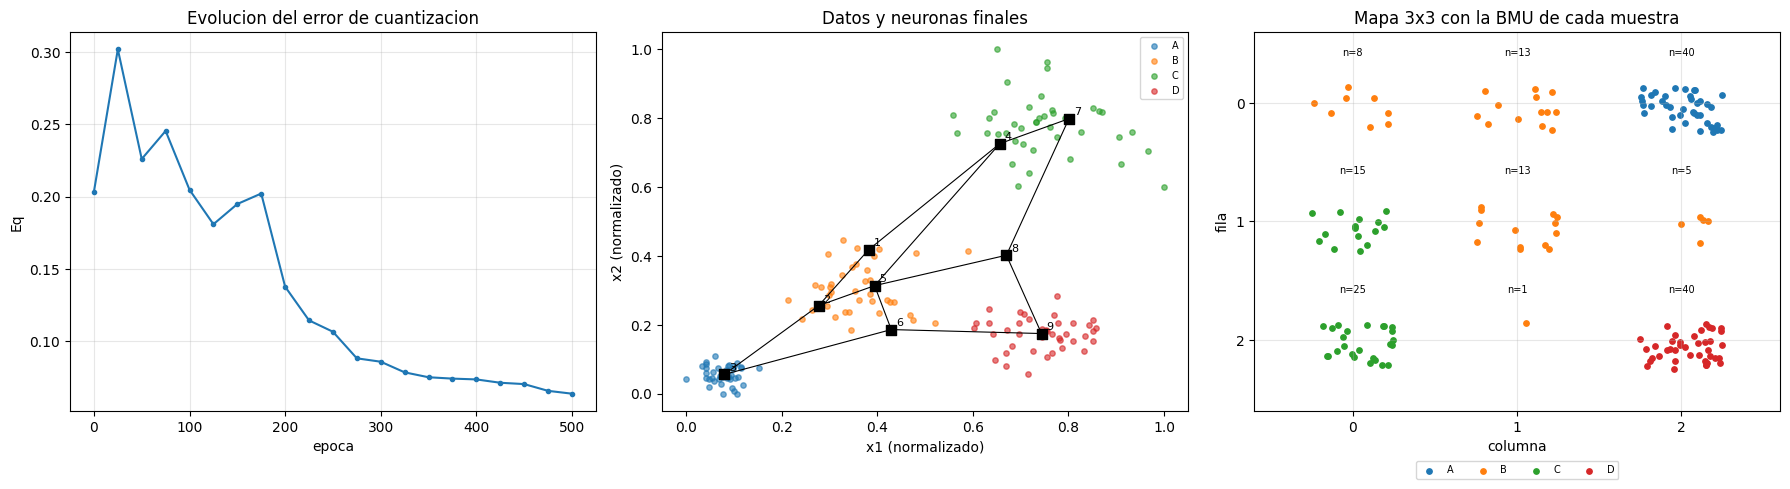

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].plot(registro4["epoca"], registro4["Eq"], marker="o", markersize=3)
ax[0].set_xlabel("epoca"); ax[0].set_ylabel("Eq")
ax[0].set_title("Evolucion del error de cuantizacion")
ax[0].grid(alpha=0.3)

graficar_datos_y_neuronas(ax[1], X4_train, y_train, pesos_fin4, filas, cols, columnas4, colores4)
graficar_mapa(ax[2], bmu_train, y_train, pos4, filas, cols, "Mapa 3x3 con la BMU de cada muestra", colores4)

plt.tight_layout()
plt.show()

## 6.8 Agrupamientos y casos fronterizos
El grupo con el que se generaron los datos no se usó en el entrenamiento; la tabla solo sirve para interpretar qué quedó en cada neurona.

In [12]:
# cuantas muestras de cada grupo le tocaron a cada neurona
composicion4 = pd.crosstab(bmu_train + 1, y_train)
composicion4.index.name = "neurona"
composicion4.columns.name = "grupo"
print(composicion4)

# casos fronterizos: muestras con poca diferencia entre la distancia a la 1a y a la 2a neurona mas cercana
ordenadas = np.argsort(D_train, axis=1)
d1 = D_train[np.arange(len(D_train)), ordenadas[:, 0]]
d2 = D_train[np.arange(len(D_train)), ordenadas[:, 1]]
fronterizos = pd.DataFrame({
    "muestra": idx_train, "BMU": ordenadas[:, 0] + 1, "segunda": ordenadas[:, 1] + 1,
    "d1": d1, "d2": d2, "d2 - d1": d2 - d1, "grupo": y_train
}).sort_values("d2 - d1").head(8)
print()
print(fronterizos.round(4).to_string(index=False))

grupo     A   B   C   D
neurona                
1         0   8   0   0
2         0  13   0   0
3        40   0   0   0
4         0   0  15   0
5         0  13   0   0
6         0   5   0   0
7         0   0  25   0
8         0   1   0   0
9         0   0   0  40

 muestra  BMU  segunda     d1     d2  d2 - d1 grupo
      57    1        5 0.0616 0.0722   0.0107     B
     128    7        4 0.1685 0.1809   0.0124     C
      64    5        1 0.0473 0.0605   0.0132     B
      52    6        2 0.0838 0.0987   0.0149     B
      58    5        6 0.0631 0.0795   0.0164     B
      96    5        1 0.0747 0.0926   0.0178     B
      79    2        5 0.0691 0.0917   0.0226     B
      53    5        6 0.0575 0.0804   0.0228     B


**Interpretación (SEMILLA_4 = 42).** El error de cuantización bajó de 0.2035 al inicio a 0.0635 con los datos de entrenamiento y 0.0740 con los de evaluación. Al principio subió hasta cerca de 0.30: con σ grande casi todas las neuronas se mueven igual que la ganadora y se juntan hacia el centro de los datos; al bajar σ se separan y el error baja.

El mapa separó los cuatro grupos sin conocerlos y ninguna neurona quedó mezclada. El grupo A quedó completo en la neurona 3 (40 muestras), el D completo en la 9 (40), el C en las neuronas 4 y 7 (15 y 25) y el B, que es el que está en medio de los demás, se repartió en cinco neuronas (1, 2, 5, 6 y 8). La neurona 8 solo ganó una muestra: está en la zona vacía entre los grupos C y D.

Los casos fronterizos de la tabla tienen una diferencia entre d1 y d2 menor a 0.03, es decir que están casi a la misma distancia de dos neuronas. Casi todos son del grupo B, entre las neuronas 1, 2, 5 y 6, o sea fronteras entre neuronas del mismo grupo, y hay uno del grupo C entre la 7 y la 4. En esta corrida no aparecen casos fronterizos entre grupos distintos porque los grupos están bastante separados.

# 7. Ejercicio 5: aplicación con Iris

Ahora usamos el conjunto Iris con sus cuatro características. La columna de especie se separa antes de entrenar y el SOM nunca la ve; solo se usa al final para colorear y analizar el mapa.

## 7.1 Preparación de datos

In [13]:
iris = pd.read_csv("iris_processed.csv")
print(iris.shape)
iris.head()

(150, 5)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [14]:
columnas5 = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
especies = iris["Species"].to_numpy()           # se guardan aparte, no se usan para entrenar
colores5 = {"Iris-setosa": "tab:blue", "Iris-versicolor": "tab:orange", "Iris-virginica": "tab:green"}

# separacion entrenamiento/evaluacion (misma proporcion de cada especie)
rng = np.random.default_rng(SEMILLA)
idx_train5, idx_eval5 = separar(especies, rng)

X5_crudo = iris[columnas5].to_numpy()           # aqui no hay etiquetas
min5 = X5_crudo[idx_train5].min(axis=0)         # normalizacion solo con entrenamiento
max5 = X5_crudo[idx_train5].max(axis=0)
X5_train = normalizar(X5_crudo[idx_train5], min5, max5)
X5_eval = normalizar(X5_crudo[idx_eval5], min5, max5)
y5_train, y5_eval = especies[idx_train5], especies[idx_eval5]
print(X5_train.shape, X5_eval.shape)
print("minimos de entrenamiento:", min5)
print("maximos de entrenamiento:", max5)

(120, 4) (30, 4)
minimos de entrenamiento: [4.3 2.  1.  0.1]
maximos de entrenamiento: [7.9 4.4 6.9 2.5]


## 7.2 Inicialización y entrenamiento (mapa 5×5)
Se usa σ₀ = 2.5, que es más o menos la mitad del lado del mapa; α₀ y las 500 épocas son los mismos.

In [15]:
filas5, cols5 = 5, 5
SIGMA0_5 = 2.5

pos5 = posiciones_mapa(filas5, cols5)
rng = np.random.default_rng(SEMILLA)
pesos_ini5 = inicializar_pesos(filas5 * cols5, 4, rng)

pesos_fin5, registro5 = entrenar(X5_train, pesos_ini5, pos5, ALFA0, SIGMA0_5, EPOCAS, rng)

seg5 = registro5[registro5["epoca"] % 50 == 0]
print(seg5.round(4).to_string(index=False))

 epoca   alfa  sigma     Eq
     0 0.5000 2.5000 0.2789
    50 0.3894 2.1162 0.2056
   100 0.3033 1.7913 0.1944
   150 0.2362 1.5163 0.1659
   200 0.1839 1.2835 0.1484
   250 0.1433 1.0865 0.1320
   300 0.1116 0.9197 0.1231
   350 0.0869 0.7785 0.1110
   400 0.0677 0.6590 0.1050
   450 0.0527 0.5578 0.1007
   500 0.0410 0.4722 0.0962


## 7.3 BMU de cada flor y evaluación

In [16]:
bmu5_train, D5_train = asignar_bmu(X5_train, pesos_fin5)
bmu5_eval, D5_eval = asignar_bmu(X5_eval, pesos_fin5)

tabla_bmu5 = pd.DataFrame({
    "muestra": np.concatenate([idx_train5, idx_eval5]),
    "conjunto": ["train"] * len(idx_train5) + ["eval"] * len(idx_eval5),
    "BMU": np.concatenate([bmu5_train, bmu5_eval]) + 1,
    "fila": np.concatenate([pos5[bmu5_train, 0], pos5[bmu5_eval, 0]]).astype(int),
    "columna": np.concatenate([pos5[bmu5_train, 1], pos5[bmu5_eval, 1]]).astype(int),
    "especie": np.concatenate([y5_train, y5_eval]),
}).sort_values("muestra")
tabla_bmu5.to_csv("bmu_ejercicio5.csv", index=False)
print(tabla_bmu5.head(8).to_string(index=False))

print()
print("Eq inicial        :", round(registro5["Eq"].iloc[0], 4))
print("Eq final (train)  :", round(error_cuantizacion(X5_train, pesos_fin5), 4))
print("Eq final (eval)   :", round(error_cuantizacion(X5_eval, pesos_fin5), 4))

 muestra conjunto  BMU  fila  columna     especie
       0    train   23     4        2 Iris-setosa
       1    train   24     4        3 Iris-setosa
       2    train   24     4        3 Iris-setosa
       3    train   24     4        3 Iris-setosa
       4    train   22     4        1 Iris-setosa
       5     eval   21     4        0 Iris-setosa
       6    train   23     4        2 Iris-setosa
       7    train   23     4        2 Iris-setosa

Eq inicial        : 0.2789
Eq final (train)  : 0.0962
Eq final (eval)   : 0.1136


## 7.4 Colorear las neuronas con la clase real
Ahora sí se usan las etiquetas, pero solo para interpretar. A cada neurona se le asigna la especie más frecuente entre las flores de entrenamiento que la tienen como BMU.

In [17]:
composicion5 = pd.crosstab(bmu5_train + 1, y5_train)
composicion5.index.name = "neurona"
composicion5.columns.name = "especie"
print(composicion5)

# especie mayoritaria de cada neurona que gano al menos una flor
etiqueta_neurona = composicion5.idxmax(axis=1)
print()
print("neuronas sin ninguna flor de entrenamiento:", 25 - len(etiqueta_neurona))

# porcentaje de flores de entrenamiento que coincide con la especie mayoritaria de su neurona
pred_train = np.array([etiqueta_neurona[k + 1] for k in bmu5_train])
print("coincidencia en entrenamiento:", round(np.mean(pred_train == y5_train), 4))

# en evaluacion (solo las flores cuya BMU tiene etiqueta)
con_etiqueta = [(k + 1) in etiqueta_neurona.index for k in bmu5_eval]
pred_eval = np.array([etiqueta_neurona[k + 1] for k, ok in zip(bmu5_eval, con_etiqueta) if ok])
y_eval_ok = y5_eval[np.array(con_etiqueta)]
print("coincidencia en evaluacion   :", round(np.mean(pred_eval == y_eval_ok), 4),
      "(" + str(len(y_eval_ok)) + " de " + str(len(y5_eval)) + " flores)")

especie  Iris-setosa  Iris-versicolor  Iris-virginica
neurona                                              
1                  0                0               7
2                  0                0              10
3                  0                0               3
4                  0                1               4
5                  0                1               2
6                  0                0               4
7                  0                0               5
8                  0                1               4
9                  0                1               0
10                 0                6               0
11                 0                8               0
12                 0                3               0
13                 0                5               1
14                 0                9               0
15                 0                5               0
21                 6                0               0
22                 8        

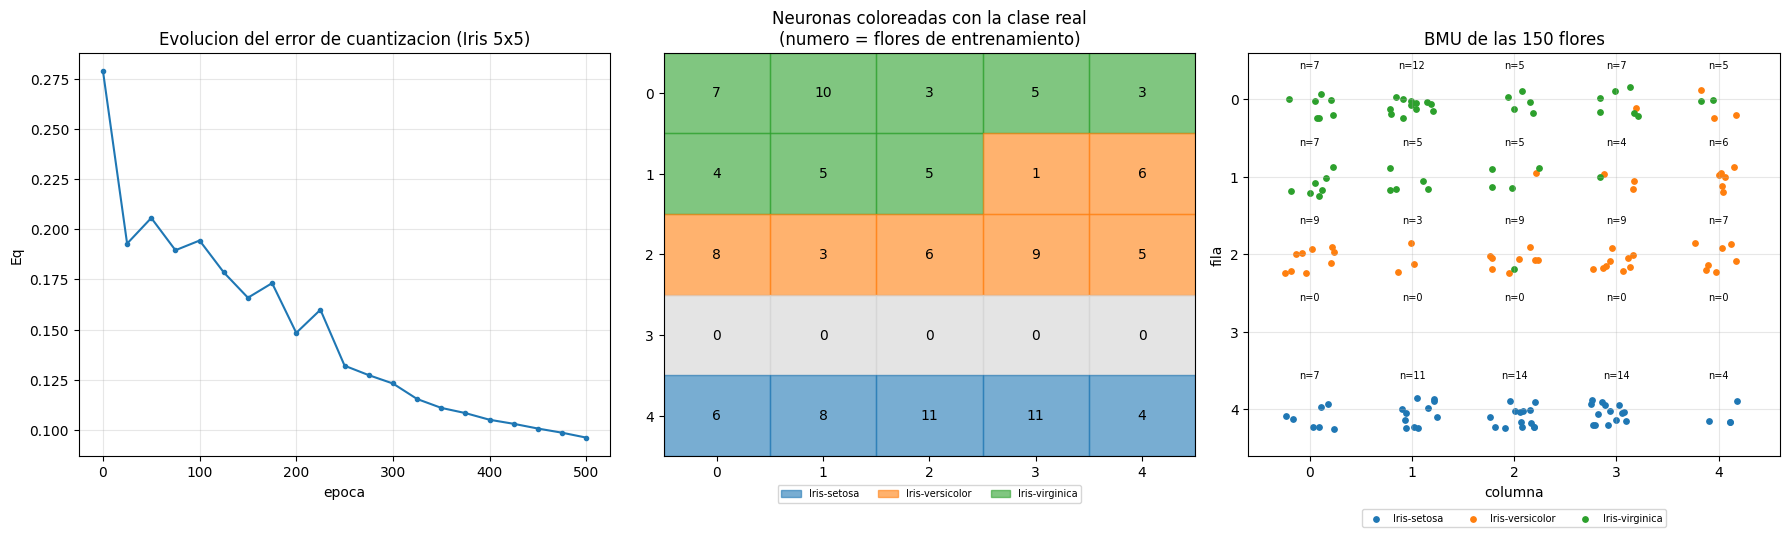

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))

ax[0].plot(registro5["epoca"], registro5["Eq"], marker="o", markersize=3)
ax[0].set_xlabel("epoca"); ax[0].set_ylabel("Eq")
ax[0].set_title("Evolucion del error de cuantizacion (Iris 5x5)")
ax[0].grid(alpha=0.3)

# mapa con las neuronas coloreadas por su especie mayoritaria
cuenta5 = np.bincount(bmu5_train, minlength=25)
for k in range(25):
    f, c = pos5[k]
    if (k + 1) in etiqueta_neurona.index:
        color = colores5[etiqueta_neurona[k + 1]]
    else:
        color = "lightgray"
    ax[1].add_patch(plt.Rectangle((c - 0.5, f - 0.5), 1, 1, color=color, alpha=0.6))
    ax[1].text(c, f, str(cuenta5[k]), ha="center", va="center")
ax[1].set_xlim(-0.5, 4.5); ax[1].set_ylim(4.5, -0.5)
ax[1].set_xticks(range(5)); ax[1].set_yticks(range(5))
ax[1].set_title("Neuronas coloreadas con la clase real\n(numero = flores de entrenamiento)")
ax[1].legend([plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.6) for c in colores5.values()],
             list(colores5.keys()), fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=3)

todas_bmu = np.concatenate([bmu5_train, bmu5_eval])
todas_esp = np.concatenate([y5_train, y5_eval])
graficar_mapa(ax[2], todas_bmu, todas_esp, pos5, 5, 5, "BMU de las 150 flores", colores5)

plt.tight_layout()
plt.show()

## 7.5 Análisis
**Regiones por especie (SEMILLA = 42).** Setosa ocupa la parte baja del mapa (neuronas 20 a 25) y no se mezcla con ninguna otra especie; entre ella y el resto hay una fila de neuronas que no ganó ninguna flor de entrenamiento (neuronas 16 a 19), lo que indica una separación grande en el espacio de datos. Versicolor ocupa la zona central y virginica la parte alta. Esas dos especies sí son vecinas y comparten algunas neuronas (por ejemplo la 5, la 8, la 9 y la 10), que es donde el mapa tiene más dudas. El error de cuantización bajó de 0.2979 a 0.0987 en entrenamiento y quedó en 0.1203 en evaluación. La especie mayoritaria de la neurona coincide con la real en el 96.7 % de las flores de entrenamiento y en el 86.7 % de las de evaluación (26 de 30).

**¿Por qué usar las etiquetas durante el entrenamiento dejaría de ser aprendizaje no supervisado?** Porque el entrenamiento dejaría de depender solo de los datos: por ejemplo, si solo se actualizaran neuronas de la misma clase que la muestra, o si se corrigiera la neurona cuando su clase no coincide, la respuesta correcta estaría guiando el ajuste de los pesos, que es justo lo que define al aprendizaje supervisado. Aquí el SOM solo ve las cuatro medidas y las especies se usan después, para interpretar.

**BMU y clase.** Una BMU es una neurona (un prototipo) que gana por cercanía; una clase es una etiqueta externa. Varias neuronas pueden representar la misma especie, y una neurona puede recibir flores de más de una (como las mezcladas de versicolor y virginica), por eso a las neuronas se les asigna una clase solo después, por mayoría.